# Reliability diagrams on the test set (final model)

Final model: single split (no folds), CT + box mask input, class-weighted cross-entropy loss (`train_no_fold.py --mask --loss weighted`), runs in `runs/cls_no_fold_mask_weighted`. Each model's class weights come from its own training targets: model A from the median ratings, model B (retrained) from the readers' shares. Figures are saved in `results/test_no_fold_mask_redoweights`.

Calibration of models A and B on the 290 test nodules: for each confidence bin, the proportion of nodules whose
predicted rating matches the median rating, compared with the dashed diagonal (perfect calibration).

**Mean over the 3 seeds:** in each bin, the number of nodules and the number predicted correctly are each averaged
over seeds 1-3, and the bar is (mean correct) / (mean nodules). The 3 cancels, so the bar heights and the ECE are the
same as pooling the seeds; only the counts change, so that they relate to the 290 test nodules.
**Error bars:** the lowest and highest proportion of the 3 seeds in that bin (seeds with no nodules in the bin are skipped).
**n:** the mean number of test nodules in the bin. Pale bars: n below 10, too few for a reliable proportion.
**Reading them:** bars above the diagonal = underconfident (right more often than it claims), below = overconfident.

The ECE in each title is calculated from these mean bins, which equals the ECE of the 3 seeds' predictions taken together. It is not the same as the ECE in `summary.csv`, which is the mean of the 3 seeds' separate ECEs.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()
sys.path.insert(0, str(PROJECT / "Model"))       # plots.py
sys.path.insert(0, str(PROJECT / "pipeline"))    # metrics.py
import metrics as M
from plots import SURFACE, INK, INK_2, MUTED, GRID, VAL, BLUES, DASHED, _style

RUNS_DIR = PROJECT / "runs" / "cls_no_fold_mask_weighted"
OUT_DIR = PROJECT / "results" / "test_no_fold_mask_redoweights"   # saved next to the other test results of this model
SEEDS = [1, 2, 3]
RATINGS = [1, 2, 3, 4, 5]
P_COLS = [f"p{k}" for k in RATINGS]
KINDS = {"hard": "A", "soft": "B"}

# check these are the final model's runs: CT + mask input, class-weighted loss
for kind in KINDS:
    for s in SEEDS:
        cfg = json.loads((RUNS_DIR / f"{kind}_seed{s}" / "config.json").read_text())
        assert cfg.get("mask") and cfg.get("loss") == "weighted", f"{kind}_seed{s} is not a mask + weighted run"
        if kind == "soft":     # the redone model B: class weights from the readers' shares, not the median ratings
            assert cfg.get("weights_from") == "readers' shares", f"soft_seed{s} still has the old median-rating weights"

labels = pd.read_csv(PROJECT / "data" / "nodules_labels.csv")
test = labels[labels["split"] == "test"].set_index("nodule_key")
hard = test["hard"].to_numpy()
print(f"{len(test)} test nodules")

def probs_of(run):
    """One run's test probabilities, rows in the order of the test nodules."""
    preds = pd.read_csv(RUNS_DIR / run / "test_preds.csv").set_index("nodule_key")
    return preds.loc[test.index, P_COLS].to_numpy()

290 test nodules


## Per bin: mean nodules, mean correct, and each seed's proportion

In [2]:
import warnings

EDGES = np.linspace(0, 1, 11)          # 10 equal-width confidence bins, as in metrics.ece()

def bin_table(kind):
    """One row per confidence bin: mean nodules and mean correct over the seeds, and each seed's proportion correct."""
    per_seed = []
    for s in SEEDS:
        probs = probs_of(f"{kind}_seed{s}")
        conf = probs.max(axis=1)
        correct = (probs.argmax(axis=1) + 1) == hard
        rows = []
        for lo, hi in zip(EDGES[:-1], EDGES[1:]):
            m = (conf > lo) & (conf <= hi)
            rows.append((m.sum(), correct[m].sum()))
        per_seed.append(np.array(rows))
    per_seed = np.array(per_seed)                       # (seeds, bins, [nodules, correct])
    nodules, right = per_seed[..., 0], per_seed[..., 1]
    with np.errstate(invalid="ignore", divide="ignore"):
        seed_prop = np.where(nodules > 0, right / nodules, np.nan)
    table = pd.DataFrame({"bin": [f"{lo:.1f}-{hi:.1f}" for lo, hi in zip(EDGES[:-1], EDGES[1:])],
                          "mean_nodules": nodules.mean(axis=0), "mean_correct": right.mean(axis=0)})
    with np.errstate(invalid="ignore", divide="ignore"):
        table["proportion"] = table["mean_correct"] / table["mean_nodules"]
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)          # all-empty bins give NaN, not a warning
        table["lowest_seed"] = np.nanmin(seed_prop, axis=0)      # seeds with no nodules in the bin are NaN, so skipped
        table["highest_seed"] = np.nanmax(seed_prop, axis=0)
    return table

tables = {kind: bin_table(kind) for kind in KINDS}
tables["hard"].round(3)

,bin,mean_nodules,mean_correct,proportion,lowest_seed,highest_seed
0,0.0-0.1,0.000,0.000,NaN,NaN,NaN
1,0.1-0.2,0.000,0.000,NaN,NaN,NaN
2,0.2-0.3,0.000,0.000,NaN,NaN,NaN
3,0.3-0.4,3.667,1.000,0.273,0.167,0.400
4,0.4-0.5,54.667,27.000,0.494,0.383,0.596
5,0.5-0.6,114.667,67.667,0.590,0.588,0.592
6,0.6-0.7,71.333,47.667,0.668,0.614,0.701
7,0.7-0.8,18.333,13.667,0.745,0.625,0.889
8,0.8-0.9,11.000,8.667,0.788,0.667,0.909
9,0.9-1.0,16.333,15.667,0.959,0.917,1.000


## Check: the ECE from these bins matches the pooled ECE

In [3]:
for kind, m in KINDS.items():
    pooled = np.concatenate([probs_of(f"{kind}_seed{s}") for s in SEEDS])
    h = np.tile(hard, len(SEEDS))
    conf = pooled.max(axis=1)                  # each bin's mean confidence, over the 3 seeds
    ece = 0.0                                  # sum over bins of (share of nodules) x |proportion correct - mean confidence|
    for lo, hi, row in zip(EDGES[:-1], EDGES[1:], tables[kind].itertuples()):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.any():
            ece += (row.mean_nodules / len(hard)) * abs(row.proportion - conf[in_bin].mean())
    print(f"model {m}: ECE from the mean bins {ece:.4f}, metrics.ece on the 3 seeds together {M.ece(pooled, h):.4f}")

model A: ECE from the mean bins 0.0319, metrics.ece on the 3 seeds together 0.0319
model B: ECE from the mean bins 0.1251, metrics.ece on the 3 seeds together 0.1251


## Draw the diagrams

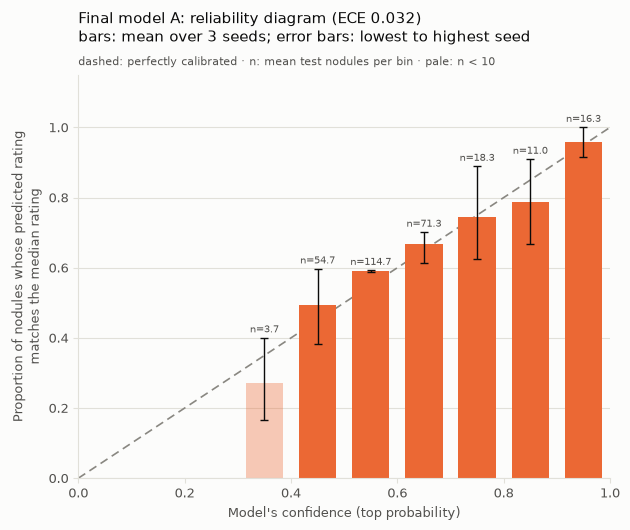

results/test_no_fold_mask_redoweights/reliability_hard_mean.png


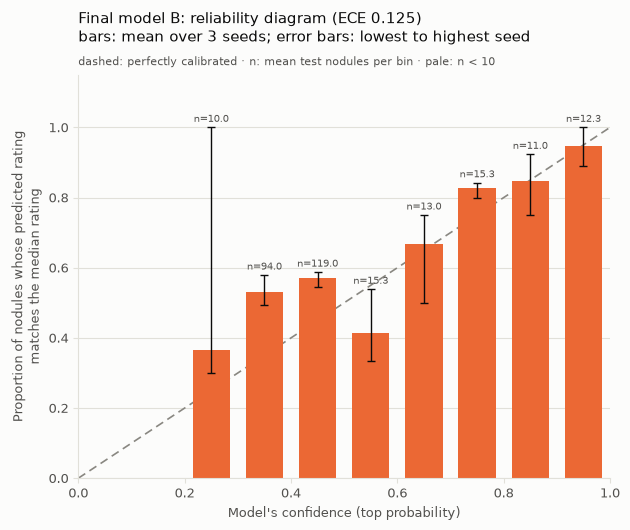

results/test_no_fold_mask_redoweights/reliability_soft_mean.png


In [4]:
def reliability(kind, model, path, min_n=10):
    t = tables[kind]
    pooled = np.concatenate([probs_of(f"{kind}_seed{s}") for s in SEEDS])
    ece = M.ece(pooled, np.tile(hard, len(SEEDS)))
    centres = (EDGES[:-1] + EDGES[1:]) / 2

    fig, ax = plt.subplots(figsize=(6.4, 5.4), facecolor=SURFACE)
    _style(ax, f"Final model {model}: reliability diagram (ECE {ece:.3f})\n"
               f"bars: mean over 3 seeds; error bars: lowest to highest seed", pad=24)
    ax.annotate(f"dashed: perfectly calibrated · n: mean test nodules per bin · pale: n < {min_n}",
                xy=(0, 1), xycoords="axes fraction", xytext=(0, 5), textcoords="offset points",
                va="bottom", fontsize=8, color=INK_2)
    ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1.2, linestyle=DASHED, zorder=1)
    for c, row in zip(centres, t.itertuples()):
        if row.mean_nodules == 0:
            continue
        ax.bar(c, row.proportion, width=0.07, color=VAL, alpha=1.0 if row.mean_nodules >= min_n else 0.35, zorder=2)
        err = [[row.proportion - row.lowest_seed], [row.highest_seed - row.proportion]]
        ax.errorbar(c, row.proportion, yerr=err, color=INK, capsize=3, linewidth=1, zorder=3)
        ax.annotate(f"n={row.mean_nodules:.1f}", xy=(c, row.highest_seed), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=7, color=INK_2)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.15)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_xlabel("Model's confidence (top probability)", fontsize=9, color=INK_2)
    ax.set_ylabel("Proportion of nodules whose predicted rating\nmatches the median rating", fontsize=9, color=INK_2)
    fig.tight_layout()
    fig.savefig(path, dpi=150, facecolor=SURFACE)
    plt.show()

for kind, m in KINDS.items():
    path = OUT_DIR / f"reliability_{kind}_mean.png"
    reliability(kind, m, path)
    print(path.relative_to(PROJECT))